In [ ]:
# APS360 - ASL Alphabet Translator
# Kutlo Moseki

# ── 1. Mount Google Drive ──
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ── 2. Install dependencies ──
!pip install torch torchvision

In [ ]:
# ── 3. Imports ──
import torch
import torchvision
import torchvision.transforms as transforms
from torch import nn
import matplotlib.pyplot as plt

In [ ]:
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cu128
GPU available: True


In [ ]:
import os
from google.colab import userdata

# Securely load the token from the Colab vault
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')

print("Token loaded securely!")

Token loaded securely!


The next code block i got online, as i was learning how to link my api key from kaggle to this notebook.

In [ ]:
import os
from google.colab import userdata

# 1. Securely pull Kaggle token from the Colab Secrets vault
os.environ["KAGGLE_API_TOKEN"] = userdata.get('KAGGLE_API_TOKEN')

# 2. Download the ASL dataset using the Kaggle API
!kaggle datasets download -d grassknoted/asl-alphabet

# 3. Unzip the downloaded dataset into a folder (e.g., /content/asl_data)
!unzip -q asl-alphabet.zip -d /content/asl_data

print("Dataset successfully downloaded and unzipped!")

Dataset URL: https://www.kaggle.com/datasets/grassknoted/asl-alphabet
License(s): GPL-2.0
asl-alphabet.zip: Skipping, found more recently modified local copy (use --force to force download)
replace /content/asl_data/asl_alphabet_test/asl_alphabet_test/A_test.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: Dataset successfully downloaded and unzipped!


In [ ]:
# ── 4.2 Data Transformation and Loading ──
from torchvision.datasets import ImageFolder
from torchvision import datasets, transforms
from torch.utils.data import random_split, DataLoader
import numpy as np

# Resize images to 224x224 (standard for most CNNs) and convert to tensor
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

# Load dataset (pointing to the train folder from the unzipped Kaggle data)
# Note: Check the exact unzipped folder path, it might be slightly different
dataset_path = '/content/asl_data/asl_alphabet_train/asl_alphabet_train'
full_dataset = ImageFolder(root=dataset_path, transform=transform)

# Print stats for your report!
print(f"Total number of images: {len(full_dataset)}")
print(f"Classes: {full_dataset.classes}")

# Split into Train (80%) and Validation (20%)
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)



Total number of images: 87000
Classes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'del', 'nothing', 'space']


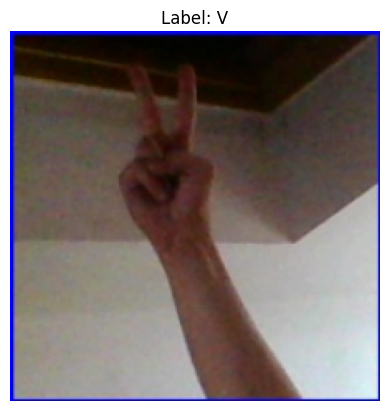

In [ ]:
import matplotlib.pyplot as plt
# ── 4.3 Visual Example for Report ──
# Grab one batch and plot the first image
images, labels = next(iter(train_loader))
plt.imshow(np.transpose(images[0].numpy(), (1, 2, 0)))
plt.title(f"Label: {full_dataset.classes[labels[0]]}")
plt.axis('off')
plt.show() # Image to attach in the progress report!

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class BaselineCNN(nn.Module):
    def __init__(self, num_classes):
        super(BaselineCNN, self).__init__()
        # Input: 3 color channels (RGB). Output: 16 feature maps. Kernel size: 3x3
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        # Pooling layer to cut image dimensions in half (224x224 -> 112x112)
        self.pool = nn.MaxPool2d(2, 2)

        # Fully connected layer. 16 channels * 112 * 112
        self.fc1 = nn.Linear(16 * 112 * 112, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = x.view(-1, 16 * 112 * 112) # Flatten the tensor
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Initialize the model using the number of classes we found in Section 4.2
num_classes = len(full_dataset.classes)
model = BaselineCNN(num_classes=num_classes)
print(model)

BaselineCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=200704, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=29, bias=True)
)


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

def get_accuracy(model, data_loader, device):
    correct = 0
    total = 0
    model.eval() # Set model to evaluation mode
    with torch.no_grad():
        for imgs, labels in data_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            output = model(imgs)
            _, predicted = torch.max(output, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return correct / total

def plot_learning_curves(train_losses, val_losses, train_accs, val_accs):
    epochs = range(1, len(train_losses) + 1)
    plt.figure(figsize=(12, 5))

    # Loss Subplot
    plt.subplot(1, 2, 1)
    plt.plot(epochs, train_losses, label='Training Loss', color='blue', marker='o')
    plt.plot(epochs, val_losses, label='Validation Loss', color='orange', marker='s')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    # Accuracy Subplot
    plt.subplot(1, 2, 2)
    plt.plot(epochs, train_accs, label='Training Accuracy', color='blue', marker='o')
    plt.plot(epochs, val_accs, label='Validation Accuracy', color='orange', marker='s')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

def train(model, train_loader, val_loader, device, num_epochs=3, learning_rate=0.001):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    train_losses, val_losses, train_accs, val_accs = [], [], [], []

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0

        for i, (imgs, labels) in enumerate(train_loader):
            imgs, labels = imgs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            if (i+1) % 50 == 0:
                print(f'Epoch [{epoch+1}/{num_epochs}], Step [{i+1}/{len(train_loader)}], Loss: {loss.item():.4f}')

        epoch_train_loss = running_loss / len(train_loader)

        model.eval()
        running_val_loss = 0.0
        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = model(imgs)
                val_loss = criterion(outputs, labels)
                running_val_loss += val_loss.item()

        epoch_val_loss = running_val_loss / len(val_loader)

        train_acc = get_accuracy(model, train_loader, device)
        val_acc = get_accuracy(model, val_loader, device)

        train_losses.append(epoch_train_loss)
        val_losses.append(epoch_val_loss)
        train_accs.append(train_acc)
        val_accs.append(val_acc)

        print(f'--- Epoch {epoch+1} Summary ---')
        print(f'Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}')
        print(f'Train Acc: {train_acc * 100:.2f}% | Val Acc: {val_acc * 100:.2f}%')

    print("Baseline training complete!")
    return train_losses, val_losses, train_accs, val_accs

In [ ]:
# 1. Setup Device (using GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training on device: {device}")

# 2. Ensure model is instantiated and sent to the GPU
num_classes = len(full_dataset.classes)
model = BaselineCNN(num_classes=num_classes).to(device)

# 3. Call the train function and save the returned lists
train_losses, val_losses, train_accs, val_accs = train(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    device=device,
    num_epochs=3,
    learning_rate=0.001
)

Training on device: cuda
Epoch [1/3], Step [50/1088], Loss: 3.2623
Epoch [1/3], Step [100/1088], Loss: 3.0107
Epoch [1/3], Step [150/1088], Loss: 2.1982
Epoch [1/3], Step [200/1088], Loss: 2.2333
Epoch [1/3], Step [250/1088], Loss: 1.8280
Epoch [1/3], Step [300/1088], Loss: 1.9369
Epoch [1/3], Step [350/1088], Loss: 1.6392
Epoch [1/3], Step [400/1088], Loss: 1.6815
Epoch [1/3], Step [450/1088], Loss: 1.4086
Epoch [1/3], Step [500/1088], Loss: 1.3918
Epoch [1/3], Step [550/1088], Loss: 1.2736
Epoch [1/3], Step [600/1088], Loss: 1.3622
Epoch [1/3], Step [650/1088], Loss: 1.2123
Epoch [1/3], Step [700/1088], Loss: 1.1869
Epoch [1/3], Step [750/1088], Loss: 1.1046
Epoch [1/3], Step [800/1088], Loss: 0.8960
Epoch [1/3], Step [850/1088], Loss: 0.7702
Epoch [1/3], Step [900/1088], Loss: 1.0259
Epoch [1/3], Step [950/1088], Loss: 0.9775
Epoch [1/3], Step [1000/1088], Loss: 0.5967
Epoch [1/3], Step [1050/1088], Loss: 0.6811
--- Epoch 1 Summary ---
Train Loss: 1.6411 | Val Loss: 0.7704
Train Acc

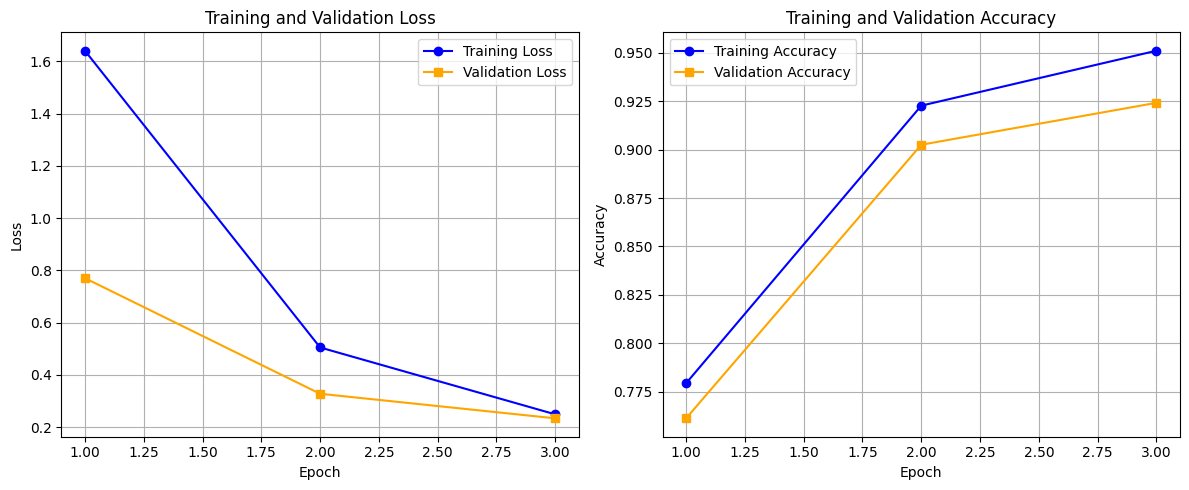

In [ ]:
# Plotting to include in my progress report
plot_learning_curves(train_losses, val_losses, train_accs, val_accs)

In [ ]:
class PrimaryCNN(nn.Module):
    def __init__(self, num_classes):
        super(PrimaryCNN, self).__init__()
        self.name = "PrimaryCNN"

        # Block 1: 3 channels in, 32 out. 224x224 -> 112x112
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(2, 2)

        # Block 2: 32 channels in, 64 out. 112x112 -> 56x56
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(2, 2)

        # Fully Connected layers
        # After two 2x2 pools, the 224x224 image is 56x56.
        self.fc1 = nn.Linear(64 * 56 * 56, 256)
        self.dropout = nn.Dropout(0.5) # Drops 50% of neurons to prevent overfitting
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool2(F.relu(self.conv2(x)))
        x = x.view(-1, 64 * 56 * 56) # Flatten
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

In [ ]:
# Instantiate my new model and send it to the GPU
primary_model = PrimaryCNN(num_classes=num_classes).to(device)

print("Starting training for Primary Model...")
# Call the existing train function again
p_train_losses, p_val_losses, p_train_accs, p_val_accs = train(
    model=primary_model,
    train_loader=train_loader,
    val_loader=val_loader,
    device=device,
    num_epochs=5,       # Running for 5 epochs
    learning_rate=0.001
)

# Save the trained primary model
torch.save(primary_model.state_dict(), 'best_model.pth')

Starting training for Primary Model...
Epoch [1/5], Step [50/1088], Loss: 3.3660
Epoch [1/5], Step [100/1088], Loss: 3.3686
Epoch [1/5], Step [150/1088], Loss: 3.3300
Epoch [1/5], Step [200/1088], Loss: 2.7015
Epoch [1/5], Step [250/1088], Loss: 2.6172
Epoch [1/5], Step [300/1088], Loss: 2.4151
Epoch [1/5], Step [350/1088], Loss: 2.0913
Epoch [1/5], Step [400/1088], Loss: 2.2772
Epoch [1/5], Step [450/1088], Loss: 2.0544
Epoch [1/5], Step [500/1088], Loss: 2.1151
Epoch [1/5], Step [550/1088], Loss: 1.9258
Epoch [1/5], Step [600/1088], Loss: 1.9068
Epoch [1/5], Step [650/1088], Loss: 1.5689
Epoch [1/5], Step [700/1088], Loss: 1.7558
Epoch [1/5], Step [750/1088], Loss: 1.5300
Epoch [1/5], Step [800/1088], Loss: 1.6272
Epoch [1/5], Step [850/1088], Loss: 1.5049
Epoch [1/5], Step [900/1088], Loss: 1.7757
Epoch [1/5], Step [950/1088], Loss: 1.5909
Epoch [1/5], Step [1000/1088], Loss: 1.5993
Epoch [1/5], Step [1050/1088], Loss: 1.3315
--- Epoch 1 Summary ---
Train Loss: 2.2153 | Val Loss: 1.

Primary Model Learning Curves:


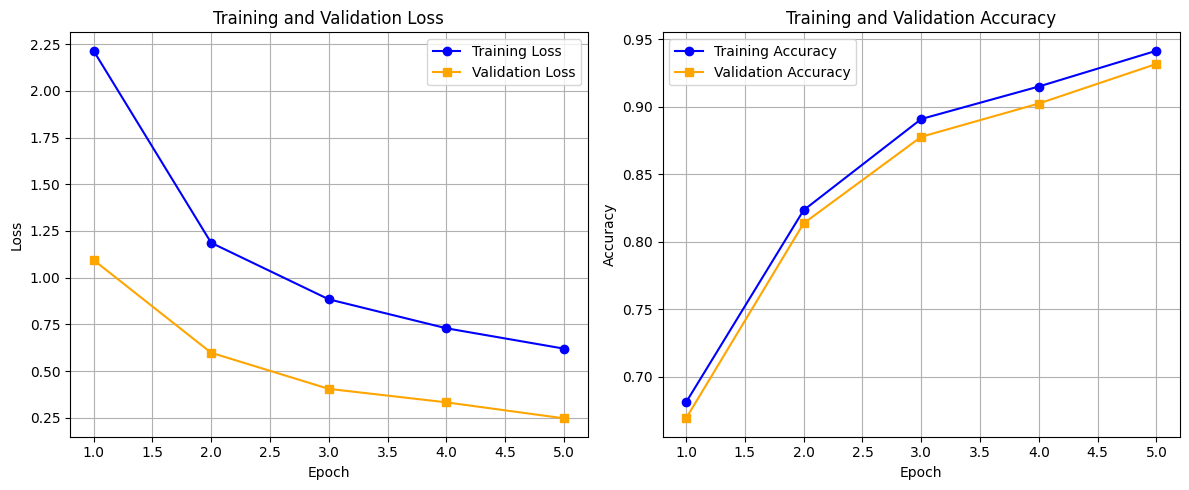

In [ ]:
#Plotting my custom primary model
print("Primary Model Learning Curves:")
plot_learning_curves(p_train_losses, p_val_losses, p_train_accs, p_val_accs)

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def get_predictions(model, data_loader, device):
    """
    Passes data through the model and returns lists of true and predicted labels.
    """
    model.eval() # Set model to evaluation mode
    all_preds = []
    all_labels = []

    with torch.no_grad(): # Disable gradient calculation for memory efficiency
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)

            # Forward pass
            outputs = model(images)

            # Get the predicted class (highest probability)
            _, preds = torch.max(outputs, 1)

            # Move data back to CPU and convert to numpy lists
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    return all_labels, all_preds

# --- How to use it ---
# 1. Ensure you have  device set up
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Make sure your model(s) are on the correct device
model.to(device)
primary_model.to(device)
# 3. Generate the Confusion Matrix
cm = confusion_matrix(true_labels, predicted_labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

# 4. Plot the Baseline Model's Confusion Matrix with Numbers
# Increased figsize to 12x12 or 15x15 to ensure the numbers fit inside the grid
fig, ax = plt.subplots(figsize=(15, 15))

# Added include_values=True and values_format='d' (for integers)
disp.plot(ax=ax, cmap=plt.cm.Blues, xticks_rotation='vertical', include_values=True, values_format='d')

plt.title("Validation Confusion Matrix - Baseline Model")
plt.show()

NameError: name 'true_labels' is not defined

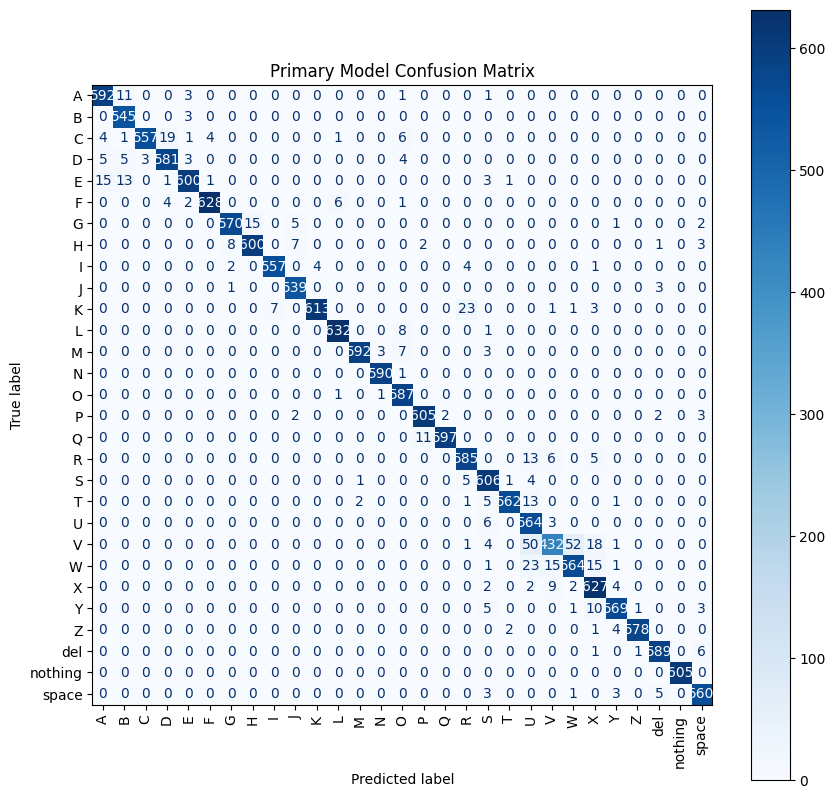

In [ ]:
# 1. Ensure the primary model is on the right device (safety net)
primary_model.to(device)

# 2. Get predictions specifically for the primary model
labels_prim, preds_prim = get_predictions(primary_model, val_loader, device)

# 3. Generate the confusion matrix using scikit-learn
cm_prim = confusion_matrix(labels_prim, preds_prim)

# 4. Plot the confusion matrix
disp_prim = ConfusionMatrixDisplay(confusion_matrix=cm_prim, display_labels=val_dataset.dataset.classes)


fig, ax = plt.subplots(figsize=(10, 10))
disp_prim.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation='vertical')
plt.title("Primary Model Confusion Matrix")
plt.show()

#Testing the custom dataset


In [ ]:
#unzipping my custom dataset, forcing overwrite to ensure clean extraction
!unzip -o ASL_customtest.zip -d ./

unzip:  cannot find or open ASL_customtest.zip, ASL_customtest.zip.zip or ASL_customtest.zip.ZIP.


In [ ]:
!pip install pillow-heif

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 75.6 MB/s eta 0:00:00


In [ ]:
import os
from PIL import Image
import pillow_heif

# Register the HEIC plugin with standard Pillow
pillow_heif.register_heif_opener()

dataset_dir = './ASL_customtest'
converted_count = 0

print("Scanning and converting images... ")

for root, dirs, files in os.walk(dataset_dir):
    for file in files:
        # Check all files named .jpg
        if file.lower().endswith('.jpg'):
            file_path = os.path.join(root, file)
            try:
                # Open the file (plugin handles the HEIC format)
                with Image.open(file_path) as img:
                    # Convert to standard RGB to drop any Apple-specific transparency layers
                    rgb_img = img.convert('RGB')
                    # Save it back to the exact same path as a true JPEG
                    rgb_img.save(file_path, 'JPEG')
                    converted_count += 1
            except Exception as e:
                print(f"Failed to process {file_path}. Error: {e}")

print(f"Success! Converted {converted_count} files into true JPEGs.")

Scanning and converting images... 
Success! Converted 145 files into true JPEGs.


In [ ]:
import torch
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
import os
import shutil
from PIL import Image # Import Pillow for image validation

# --- Clean up __MACOSX directories and .DS_Store files ---
# This is a common issue with datasets zipped on macOS
# and can cause problems for ImageFolder.

# Remove __MACOSX directory if it exists
if os.path.exists('./__MACOSX'):
    print("Removing __MACOSX directory...")
    shutil.rmtree('./__MACOSX')

# Remove .DS_Store files within ASL_customtest
for root, dirs, files in os.walk('./ASL_customtest'):
    for file in files:
        if file == '.DS_Store':
            file_path = os.path.join(root, file)
            print(f"Removing {file_path}...")
            os.remove(file_path)

# --- Image Validation and Cleanup ---
print("Validating images in ASL_customtest directory...")
corrupted_files = []
for root, dirs, files in os.walk('./ASL_customtest'):
    for file in files:
        file_path = os.path.join(root, file)
        try:
            # Attempt to open the image to check for corruption
            with Image.open(file_path) as img:
                img.verify() # Verify that the file is an image
        except (IOError, SyntaxError, Image.UnidentifiedImageError) as e:
            print(f"Corrupted or unidentifiable image found: {file_path}. Error: {e}")
            corrupted_files.append(file_path)
'''
# Remove corrupted files
for file_path in corrupted_files:
    os.remove(file_path)
    print(f"Removed corrupted file: {file_path}")'''

# here im defining the evaluation transform pipeline
custom_transforms = transforms.Compose([
    transforms.Resize((224, 224)),            # Resizes cropped image to model input dimensions
    transforms.ToTensor(),                   # Converts PIL image to PyTorch FloatTensor [0.0, 1.0]
    transforms.Normalize(                    # Normalizes using standard ImageNet or custom stats
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Then i load the custom dataset automatically mapping folders to classes
custom_dataset = ImageFolder(root='./ASL_customtest', transform=custom_transforms)

# DataLoader for evaluation
custom_loader = DataLoader(custom_dataset, batch_size=16, shuffle=False)

print(f"Loaded {len(custom_dataset)} custom test images.")
print(f"Class mapping: {custom_dataset.class_to_idx}")

Validating images in ASL_customtest directory...
Loaded 145 custom test images.
Class mapping: {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'H': 7, 'I': 8, 'J': 9, 'K': 10, 'L': 11, 'M': 12, 'N': 13, 'O': 14, 'P': 15, 'Q': 16, 'R': 17, 'S': 18, 'T': 19, 'U': 20, 'V': 21, 'W': 22, 'X': 23, 'Y': 24, 'Z': 25, 'del': 26, 'nothing': 27, 'space': 28}


In [ ]:
import os

# Shows the folder Python is currently looking in
print("Current Directory:", os.getcwd())

# Lists all files in that exact folder
print("Files in this directory:", os.listdir())

Current Directory: /content
Files in this directory: ['.config', 'drive', 'ASL_customtest', 'asl-alphabet.zip', '__MACOSX', 'ASL_customtest.zip', 'asl_data', 'sample_data']


In [ ]:
import os

print("Searching Google Drive for the model...")
for root, dirs, files in os.walk('/content/drive'):
    if 'best_model.pth' in files:
        print("Found it! Update your path to:")
        print(os.path.join(root, 'best_model.pth'))

Searching Google Drive for the model...


In [ ]:
import torch
import torch.nn as nn

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

num_classes = 29
# Load your pre-trained model architecture and state dict
primary_model = PrimaryCNN(num_classes=num_classes).to(device)

# Before loading, you need to save the model after training.
# For example, after training in cell RkYHNzWSSTcx, you could add:
# torch.save(primary_model.state_dict(), 'best_model.pth')
# Then this line will work:
primary_model.load_state_dict(torch.load('best_model.pth', map_location=device))
primary_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in custom_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = primary_model(images)
        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

custom_accuracy = 100 * correct / total
print(f'Custom Dataset Accuracy: {custom_accuracy:.2f}%')

Custom Dataset Accuracy: 3.45%


In [ ]:
!pip install "rembg[gpu]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 249.8/249.8 MB 5.1 MB/s eta 0:00:00


In [ ]:
import os
from PIL import Image
from rembg import remove

input_dir = './ASL_customtest'
output_dir = './ASL_customtest_whitebg' # Saving to a new folder to be safe

print("Starting background removal... This will take a minute or two.")

# Create the main output directory
os.makedirs(output_dir, exist_ok=True)

processed_count = 0

for root, dirs, files in os.walk(input_dir):
    for file in files:
        if file.lower().endswith('.jpg'):
            input_path = os.path.join(root, file)

            # Replicate the A-Z folder structure in the new directory
            rel_path = os.path.relpath(root, input_dir)
            target_dir = os.path.join(output_dir, rel_path)
            os.makedirs(target_dir, exist_ok=True)

            output_path = os.path.join(target_dir, file)

            try:
                # 1. Open your image
                input_img = Image.open(input_path)

                # 2. Strip the background (creates a transparent background)
                no_bg_img = remove(input_img)

                # 3. Create a brand new solid white image of the exact same size
                white_bg = Image.new("RGB", no_bg_img.size, (255, 255, 255))

                # 4. Paste your hand onto the white background
                # The third argument uses the transparency channel as a mask
                white_bg.paste(no_bg_img, (0, 0), no_bg_img)

                # 5. Save it as a true JPEG
                white_bg.save(output_path, "JPEG")
                processed_count += 1

            except Exception as e:
                print(f"Skipping {input_path} due to error: {e}")

print(f"Success! Processed {processed_count} images with white backgrounds.")

Starting background removal... This will take a minute or two.


  0%|                                               | 0.00/176M [00:00<?, ?B/s]

Success! Processed 145 images with white backgrounds.


In [ ]:
import torch
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
import os
import shutil
from PIL import Image # Import Pillow for image validation

# --- Clean up __MACOSX directories and .DS_Store files ---
# This is a common issue with datasets zipped on macOS
# and can cause problems for ImageFolder.

# Remove __MACOSX directory if it exists
if os.path.exists('./__MACOSX'):
    print("Removing __MACOSX directory...")
    shutil.rmtree('./__MACOSX')

# Remove .DS_Store files within ASL_customtest
for root, dirs, files in os.walk('./ASL_customtest'):
    for file in files:
        if file == '.DS_Store':
            file_path = os.path.join(root, file)
            print(f"Removing {file_path}...")
            os.remove(file_path)

# --- Image Validation and Cleanup ---
print("Validating images in ASL_customtest directory...")
corrupted_files = []
for root, dirs, files in os.walk('./ASL_customtest'):
    for file in files:
        file_path = os.path.join(root, file)
        try:
            # Attempt to open the image to check for corruption
            with Image.open(file_path) as img:
                img.verify() # Verify that the file is an image
        except (IOError, SyntaxError, Image.UnidentifiedImageError) as e:
            print(f"Corrupted or unidentifiable image found: {file_path}. Error: {e}")
            corrupted_files.append(file_path)
'''
# Remove corrupted files
for file_path in corrupted_files:
    os.remove(file_path)
    print(f"Removed corrupted file: {file_path}")'''

# here im defining the evaluation transform pipeline
custom_transforms = transforms.Compose([
    transforms.Resize((224, 224)),            # Resizes cropped image to model input dimensions
    transforms.ToTensor(),                   # Converts PIL image to PyTorch FloatTensor [0.0, 1.0]
    transforms.Normalize(                    # Normalizes using standard ImageNet or custom stats
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Then i load the custom dataset automatically mapping folders to classes
custom_dataset = ImageFolder(root='./ASL_customtest_whitebg', transform=custom_transforms)

custom_loader = DataLoader(custom_dataset, batch_size=16, shuffle=False)

print(f"Loaded {len(custom_dataset)} custom test images.")
print(f"Class mapping: {custom_dataset.class_to_idx}")

Validating images in ASL_customtest directory...
Loaded 145 custom test images.
Class mapping: {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'H': 7, 'I': 8, 'J': 9, 'K': 10, 'L': 11, 'M': 12, 'N': 13, 'O': 14, 'P': 15, 'Q': 16, 'R': 17, 'S': 18, 'T': 19, 'U': 20, 'V': 21, 'W': 22, 'X': 23, 'Y': 24, 'Z': 25, 'del': 26, 'nothing': 27, 'space': 28}


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# 1. Grab a single batch of images and labels from your white-background loader
dataiter = iter(custom_loader)
images, labels = next(dataiter)

# Send data to the GPU (or CPU) to match your model
images, labels = images.to(device), labels.to(device)

# 2. Run the images through your trained model to get predictions
primary_model.eval()
with torch.no_grad():
    outputs = primary_model(images)
    _, predicted = torch.max(outputs, 1)

# 3. Create a dictionary to translate model numbers (0, 1, 2) back to letters (A, B, C)
idx_to_class = {v: k for k, v in custom_dataset.class_to_idx.items()}

# 4. Set up the plotting grid (2 rows, 3 columns = 6 images)
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
axes = axes.flatten()

# Function to un-distort the PyTorch colors so they look like normal photos again
def denormalize(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = tensor.cpu().numpy().transpose((1, 2, 0))
    img = std * img + mean
    img = np.clip(img, 0, 1)
    return img

# 5. Plot the first 6 images from the batch
for i in range(6):
    ax = axes[i]
    img = denormalize(images[i])
    ax.imshow(img)
    ax.axis('off')

    # Get the actual letter and the model's predicted letter
    true_label = idx_to_class[labels[i].item()]
    pred_label = idx_to_class[predicted[i].item()]

    # Color code the titles: Green if correct, Red if wrong
    color = 'green' if true_label == pred_label else 'red'
    ax.set_title(f"Pred: {pred_label} | True: {true_label}",
                 color=color, fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

NameError: name 'custom_loader' is not defined

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class PrimaryCNN(nn.Module):
    def __init__(self, num_classes):
        super(PrimaryCNN, self).__init__()
        self.name = "PrimaryCNN"

        # Block 1: 3 channels in, 32 out. 224x224 -> 112x112
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(2, 2)

        # Block 2: 32 channels in, 64 out. 112x112 -> 56x56
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(2, 2)

        # Fully Connected layers
        # After two 2x2 pools, the 224x224 image is 56x56.
        self.fc1 = nn.Linear(64 * 56 * 56, 256)
        self.dropout = nn.Dropout(0.5) # Drops 50% of neurons to prevent overfitting
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))
        x = self.pool2(F.relu(self.conv2(x)))
        x = x.view(-1, 64 * 56 * 56) # Flatten
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x


# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

num_classes = 29
# Load your pre-trained model architecture and state dict
primary_model = PrimaryCNN(num_classes=num_classes).to(device)

# Before loading, you need to save the model after training.
# For example, after training in cell RkYHNzWSSTcx, you could add:
# torch.save(primary_model.state_dict(), 'best_model.pth')
# Then this line will work:
primary_model.load_state_dict(torch.load('best_model.pth', map_location=device))
primary_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in custom_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = primary_model(images)
        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

custom_accuracy = 100 * correct / total
print(f'Custom Dataset Accuracy: {custom_accuracy:.2f}%')


FileNotFoundError: [Errno 2] No such file or directory: 'best_model.pth'